<a href="https://colab.research.google.com/github/Jess-chege/Data-Science-projects/blob/main/SVR_model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [ ]:
#Assignment 2 Multi-Feature Regression
#importing  the dataset
data= pd.read_csv("/content/drive/MyDrive/task2_svr_data.csv")
X = data.iloc[:, 0:1].values   # 4 features
Y = data.iloc[:, 1:2].values  # columns 0,1,2,3 → Temperature, Humidity, Wind_Speed, Solar_Radiation


In [ ]:
data.head(10)

,Temperature,Ice_Cream_Sales
0,15,180
1,17,210
2,18,230
3,20,280
4,21,300
5,23,360
6,24,390
7,26,450
8,27,480
9,28,520


In [ ]:
#creating the linear regression without data scaling
from sklearn.linear_model import LinearRegression

lin_reg = LinearRegression()
lin_reg.fit(X, Y)

LinearRegression()

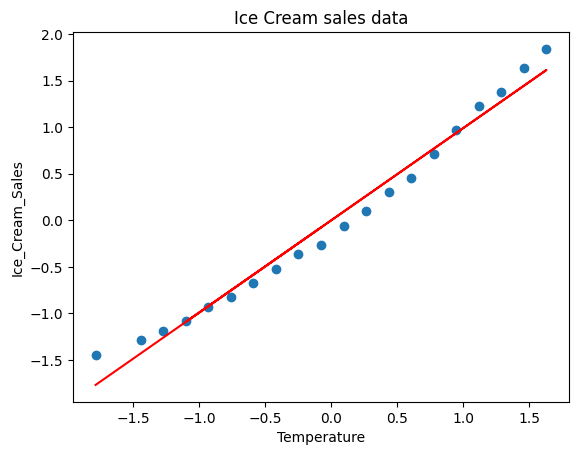

In [ ]:
#visualizing linear regression results
plt.scatter(X,Y)
plt.plot(X, lin_reg.predict(X), color='red')
plt.title('Ice Cream sales data (Linear Regression)')
plt.xlabel('Temperature')
plt.ylabel('Ice_Cream_Sales')
plt.show()

In [ ]:
#feature scaling
#anytime one is using the svr model one must do the feature scaling using the standard scaler
from sklearn.preprocessing import StandardScaler
sc_Y = StandardScaler()
sc_X = StandardScaler()
X_scaled = sc_X.fit_transform(X)
Y_scaled= sc_Y.fit_transform(Y)


In [ ]:
#Fitting the SVR Dataset
from sklearn.svm import SVR
regressor= SVR(kernel='rbf')
regressor.fit(X_scaled,Y_scaled)


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


SVR()

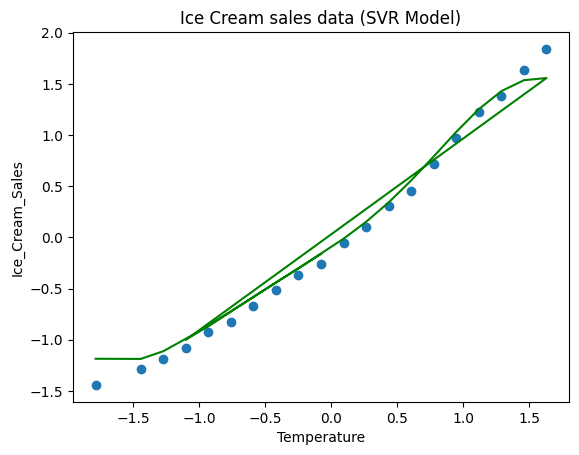

In [ ]:
#Creating visualizations to show how the SVR results appear
plt.scatter(X_scaled,Y_scaled)
plt.plot(X_scaled, regressor.predict(X_scaled), color = 'green')
plt.title('Ice Cream sales data (SVR Model)')
plt.xlabel('Temperature')
plt.ylabel('Ice_Cream_Sales')
plt.show()

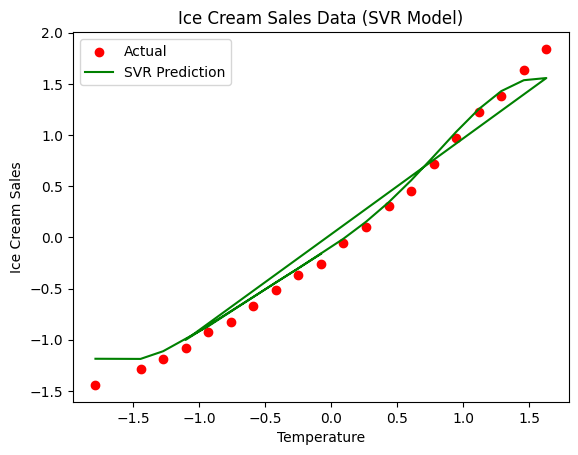

In [ ]:
#Creating an inverse transformed visualisation:
# Predict using the model
Y_pred_scaled = regressor.predict(X_scaled)

# Inverse transform X and Y to original scale
X_orig = sc_X.inverse_transform(X_scaled)
Y_orig = sc_Y.inverse_transform(Y_scaled)
Y_pred = sc_Y.inverse_transform(Y_pred_scaled.reshape(-1,1))

# Plotting
plt.scatter(X_orig, Y_orig, color='red', label='Actual')
plt.plot(X_orig, Y_pred, color='green', label='SVR Prediction')
plt.title('Ice Cream Sales Data (SVR Model)')
plt.xlabel('Temperature')
plt.ylabel('Ice Cream Sales')
plt.legend()
plt.show()

1. The Shape of the Fit (Line vs. Curve)
Linear Regression (Red Line): This model assumes a strict, constant relationship. It draws a perfectly straight line through the data. It assumes that for every degree the temperature rises, sales increase by the exact same amount, regardless of how hot it already is.
SVR Model (Green Line): This model is much more flexible. It produces a curved (non-linear) fit. We can see the line "bend" to follow the data points more closely, especially at the extreme ends (very cold or very hot temperatures).

2. Accuracy and "Goodness of Fit"
Linear Regression: Notices the residuals (the gaps between the blue dots and the red line). At the very beginning and very end of the temperature scale, the red line is quite far from the actual data points. This suggests the model is "underfitting": it's too simple to capture the real trend.
SVR Model: The green line embraces the blue dots much more effectively. In the middle of the graph, it captures the slight acceleration in sales, and at the top right, it curves upward to meet the highest data points that the linear model missed.

3. Handling the "Endpoints"
Cold Temperatures (Bottom Left): The Linear Regression line predicts sales that are lower than what the data actually shows. The SVR model flattens out slightly, correctly identifying that sales don't just drop off infinitely in a straight line.
Hot Temperatures (Top Right): The Linear model significantly under-predicts sales at the highest temperatures. The SVR model recognizes the "uprise" in sales as it gets very hot and adjusts its curve upward to reduce the error.

 Scaling the dataset is essential for SVR: Unlike Linear Regression, Support Vector Regression (SVR) is a distance-based algorithm; it cannot see the relationship correctly if one variable has much larger numbers than the other.

Scaling helps in equalizing the  Features: Scaling ensures that the model doesn't give more importance to Sales just because the numbers might be higher than Temperature; it puts both on a level playing field.

Captures the Curve: Without scaling, the SVR model most likely wouldn't have been able to calculate that smooth green curve that embraces the data points so accurately.

Mathematical Stability: It prevents the math from becoming unbalanced, allowing the optimization process to find the best-fitting line much more efficiently.